# Mesurer pour mieux rénover : de la donnée à la performance énergétique

**Assessment de stage — coEnergy, pôle R&D Software & Data Science**

Objectif : prédire, à partir de la température intérieure $T_{int}(t)$ et de la sollicitation thermique $U(t)$, le vecteur d'indicateurs

$$y = \big(\text{HLC},\ \text{HLC}_{ext},\ \text{HLC}_{mit},\ \tau_b,\ \tau_n,\ \tau_\infty\big)$$

Ce notebook est le rapport exécutable. Tout le code réutilisable est dans le paquet `coenergy` (`src/coenergy/`) ; les cellules ci-dessous ne font que l'appeler.

**Plan du rapport**

Ce notebook (sections 1 à 3) :
1. Compréhension physique du problème
2. Chargement des données
3. Analyse exploratoire

Suite dans `modelisation.ipynb` (sections 4 à 7) : choix méthodologiques, résultats, analyse critique
des erreurs et robustesse, conclusion. Les expériences intermédiaires sont dans `annexes/`.
Vue d'ensemble du projet : `README.md`, section « Guide de lecture ».

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from coenergy.baselines import mean_baseline, ridge_baseline
from coenergy.config import DataConfig, ModelConfig, NoiseConfig, TrainConfig
from coenergy.data import (BatchIterator, InputScaler, TargetScaler, describe_batch,
                           list_batch_files, load_simulations, load_solicitation_sample,
                           make_splits)
from coenergy.eda import (curve_svd, design_summary, duplicate_report, excitation_groups,
                          excitation_richness, fit_rc_model, group_split_overlap,
                          mean_power_spectrum, robust_outliers, snr_table, spearman_matrix,
                          spearman_table, temporal_information_profile,
                          variance_share_by_group)
from coenergy.features import excitation_descriptors, temperature_descriptors
from coenergy.metrics import (compare_models, constraint_violation, metrics_by_group,
                              metrics_table)
from coenergy.model import CNNGRU
from coenergy.plots import (plot_correlation_matrix, plot_error_vs_value, plot_learning_curves,
                            plot_parity, plot_sample_series, plot_target_distributions)
from coenergy.train import (ground_truth, load_checkpoint, predict, save_checkpoint,
                            train_model)
from coenergy.utils import count_parameters, get_device, set_seed

ROOT = Path("..").resolve()
DATA_PATH = ROOT / "data" / "quentin_house"

# 4 batchs = 200 000 simulations. Commencer par n_batches=1, n_per_batch=10_000 pour tester.
DATA_CFG = DataConfig(n_batches=4, n_per_batch=None, downsample=1, val_frac=0.1,
                      test_frac=0.1, seed=42)
NOISE_CFG = NoiseConfig(temperature_std=0.1, excitation_rel_std=0.01)
MODEL_CFG = ModelConfig()
TRAIN_CFG = TrainConfig()

set_seed(TRAIN_CFG.seed)
DEVICE = get_device()
pd.set_option("display.precision", 3)
print("Device :", DEVICE, "| torch", torch.__version__)

Device : cpu | torch 2.15.0+cpu


c:\Users\DELL\Downloads\livrable_CoEnergy\livrable\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Compréhension physique du problème

### 1.1 Le modèle thermique sous-jacent
Les données proviennent d'une **simulation thermique dynamique**. Le bâtiment est discrétisé en nœuds (air, couches des parois) dont les températures $T$ obéissent à un modèle d'état linéaire :

$$C\,\dot T = A\,T + E\,U, \qquad Y = J\,T + G\,U$$

- $C$ : capacités thermiques (inertie), $A$ : conductances entre nœuds, $U$ : entrées (météo, puissance injectée).
- $T_{int}$ est une composante de la sortie $Y$.

La réponse est une somme d'exponentielles, une par mode thermique, chacune avec sa constante de temps. **La forme de $T_{int}(t)$ en réponse à $U(t)$ contient donc l'information sur les déperditions (amplitude) et sur l'inertie (dynamique).**

### 1.2 Les indicateurs à prédire
| Famille | Indicateur | Ce qu'il mesure |
|---|---|---|
| HLC | $\text{HLC}$ (W/K) | Puissance à fournir en régime permanent pour maintenir 1 K d'écart. Calculé exactement par le gain statique : $\text{HLC} = 1/[G - JA^{-1}E]_{1,1}$ |
| Hb | $\text{HLC}_{ext}$, $\text{HLC}_{mit}$ (W/K) | Répartition du HLC entre l'extérieur et les espaces mitoyens. **Contrainte exacte : $\text{HLC} = \text{HLC}_{ext} + \text{HLC}_{mit}$** |
| CDT | $\tau_b,\ \tau_n,\ \tau_\infty$ (h) | Inertie : décharge après saturation, persistance de la fraîcheur nocturne ($t_0 = 8$ h), temps de séjour moyen d'un joule |

Le HLC ne compte que la **transmission** (conduction et ponts thermiques), pas la ventilation ni les infiltrations.

### 1.3 Hypothèses sur la génération des données
D'après la méthode mentionne dans le paper , sur laquelle repose cet assessment :
- **une seule géométrie** de bâtiment (« quentin_house »), avec des paramètres thermophysiques tirés par **Monte Carlo** (±60 % autour des valeurs nominales). Le modèle appris sera donc **spécifique à ce bâtiment** ;
- des **excitations aléatoires** de deux familles : **sinusoïde** à amplitude et période variables, et **PRBS** (créneaux tout ou rien de durées aléatoires) ;
- un **état thermique initial inconnu**, randomisé (gradient linéaire et bruit), qui perturbe le début des réponses ;
- vraisemblablement une **même météo** pour toutes les simulations, puisque la température extérieure n'est pas fournie en entrée. *(Hypothèse à confirmer.)*

### 1.4 Attentes physiques à vérifier dans l'EDA
1. $\text{HLC} = \text{HLC}_{ext} + \text{HLC}_{mit}$ à la précision machine près.
2. Tous les indicateurs sont strictement positifs.
3. $\tau_n \le \tau_\infty$ : un refroidissement court pénètre moins dans les parois qu'un refroidissement permanent. (celle la a verifie je l'ai met selon ma comprehension de paper)
4. $\tau_b$ est probablement la plus grande des trois (toute la masse est sollicitée), donc la plus difficile à identifier sur une fenêtre courte.
5. À énergie injectée égale, la montée de $T_{int}$ diminue quand le HLC augmente.

## 2. Chargement des données

Les données sont réparties en 20 fichiers `batch_*.pt` de 50 000 simulations, chacun contenant un objet `ToSaveSimul`. On commence par inspecter un fichier pour connaître le format exact des champs.

In [3]:
files = list_batch_files(DATA_PATH)
print(f"{len(files)} fichiers batch, ex. {files[0].name}")
pd.Series(describe_batch(DATA_PATH, util_dir=ROOT), name="forme / contenu").to_frame()

20 fichiers batch, ex. batch_1.pt


,forme / contenu
HLC,"(50000,) torch.float32"
CDT,"(50000, 3) torch.float32"
indoor_temperature,"(50000, 480) torch.float32"
indoor_U,"(50000, 480) torch.float32"
solicitation,"(50000, 12) torch.float32"
solicitation_field_names,"[max_power_wat, start_amplitude_wat, end_ampli..."
Hb,"(50000, 2) torch.float32"
Hb_labels,"[HLC_mit, HLC_ext]"


`util_assessement.load_simulation_data` charge et concatène **tous** les batchs, soit 1 000 000 de simulations, ce qui peut dépasser la mémoire disponible. `coenergy.data.load_simulations` charge les fichiers **un par un** et ne garde que les champs utiles des `n_batches` premiers.

In [4]:
data = load_simulations(DATA_PATH, util_dir=ROOT, n_batches=DATA_CFG.n_batches,
                        n_per_batch=DATA_CFG.n_per_batch, downsample=DATA_CFG.downsample,
                        seed=DATA_CFG.seed)
LABELS = data.indicator_labels
Y = data.indicators().numpy()

print(f"{len(data):,} simulations | {data.n_steps} pas de {data.dt_minutes:g} min "
      f"= {data.n_steps * data.dt_minutes / 60:.1f} h")
print("Indicateurs :", LABELS)
pd.DataFrame(Y, columns=LABELS).describe().T

batch_1.pt : 50000 simulations conservées
batch_2.pt : 50000 simulations conservées
batch_3.pt : 50000 simulations conservées
batch_4.pt : 50000 simulations conservées
200,000 simulations | 480 pas de 1 min = 8.0 h
Indicateurs : ['HLC', 'HLC_mit', 'HLC_ext', 'tau_b', 'tau_n', 'tau_inf']


,count,mean,std,min,25%,50%,75%,max
HLC,200000.0,232.866,31.374,111.403,210.523,231.786,254.049,359.938
HLC_mit,200000.0,120.401,26.288,47.123,100.747,118.776,138.411,231.533
HLC_ext,200000.0,112.466,17.127,54.912,100.296,112.254,124.297,180.054
tau_b,200000.0,50.004,10.087,21.650,42.789,48.842,55.924,117.679
tau_n,200000.0,11.038,2.012,5.493,9.602,10.787,12.200,24.424
tau_inf,200000.0,31.230,7.521,11.498,25.845,30.206,35.506,83.658


**Description du jeu chargé.** On travaille sur 200 000 simulations (4 batchs de 50 000). Chaque simulation comporte deux séries de 480 pas. En supposant un pas d'une minute, cohérent avec la méthode de référence, la fenêtre d'observation dure **8 h**.

| Indicateur | Moyenne | Écart-type | Coefficient de variation | Plage |
|---|---|---|---|---|
| HLC (W/K) | 233,0 | 31,4 | 13 % | 128 – 367 |
| HLC_mit (W/K) | 120,5 | 26,3 | 22 % | 46 – 222 |
| HLC_ext (W/K) | 112,5 | 17,1 | 15 % | 58 – 179 |
| τ_b (h) | 50,0 | 10,1 | 20 % | 22 – 123 |
| τ_n (h) | 11,0 | 2,0 | 18 % | 6 – 24 |
| τ_∞ (h) | 31,2 | 7,5 | 24 % | 11 – 93 |

**Observations :**

- **Ordre de grandeur.** Avec un HLC moyen d'environ 233 W/K, il faut une puissance d'environ 233 W pour maintenir 1 K d'écart de température. Cela correspond à une maison individuelle réelle, bien au-dessus de la cellule expérimentale HAMEX du paper (23 W/K).
- **Poids des déperditions mitoyennes.** HLC_mit représente en moyenne **52 %** du HLC. Plus de la moitié des pertes se font donc vers des espaces adjacents (locaux non chauffés, maison accolée), et non vers l'extérieur. HLC_mit est aussi la composante la plus dispersée (CV de 22 %, contre 15 % pour HLC_ext). On peut s'attendre à ce qu'elle soit plus difficile à prédire.
- **Variabilité du HLC atténuée.** Les paramètres thermophysiques sont tirés à ±60 % autour de leur valeur nominale, mais le HLC ne varie que de ±13 %. Le HLC est une **somme** de contributions de nombreuses parois et ponts thermiques tirés indépendamment : leurs écarts se compensent en partie, et la dispersion relative de la somme est plus faible que celle de chaque terme.
- **Hiérarchie des constantes de temps.** En moyenne, $\tau_n$ (11 h) < $\tau_\infty$ (31 h) < $\tau_b$ (50 h). La section 3.1 vérifie que cet ordre tient dans chaque simulation.
- **Fenêtre courte devant l'inertie.** La fenêtre de 8 h est comparable à $\tau_n$, mais environ 4 fois plus courte que $\tau_\infty$ et 6 fois plus courte que $\tau_b$. Pour $\tau_b$, le modèle n'observe que le tout début de la relaxation. **On s'attend donc à une précision décroissante de $\tau_n$ à $\tau_\infty$ puis à $\tau_b$**, une hypothèse confirmée par les résultats (`modelisation.ipynb`, sections 5.2 et 6.2).
- **Asymétrie des distributions.** Les maxima de $\tau_b$ (123 h) et $\tau_\infty$ (93 h) se situent respectivement à plus de 7 et 8 écarts-types de la moyenne. Les queues à droite sont marquées, ce qui justifie de prédire les constantes de temps **en échelle logarithmique**.

*Hypothèse à garder en tête : le pas de temps d'une minute n'est pas stocké dans les fichiers ; il est déduit de la méthode de référence et de la cohérence avec $t_0 = 8$ h.*

*Note : on travaille sur un sous-ensemble des batchs pour tenir en mémoire et itérer vite. Les batchs étant a priori des tirages indépendants de la même population, on le vérifie en 3.1.*

## 3. Analyse exploratoire


### 3.1 Qualité et cohérence physique des données

**Objectif.** Avant toute analyse, s'assurer que les données sont exploitables et conformes à la physique attendue. Une simulation erronée ou une incohérence non détectée fausserait toute la suite.

**Vérifications.**
1. **Qualité** : absence de valeurs manquantes dans les entrées et les cibles, positivité de tous les indicateurs.
2. **Contrainte de décomposition** : on mesure l'écart maximal $|\text{HLC} - (\text{HLC}_{mit} + \text{HLC}_{ext})|$ pour vérifier que la relation annoncée est exacte.
3. **Hiérarchie des constantes de temps** : on vérifie que $\tau_n \le \tau_\infty$ (une sollicitation de 8 h pénètre moins dans les parois qu'une sollicitation permanente) et que $\tau_b$ est la plus grande (toute la masse du bâti est mobilisée).
4. **Nature de la sollicitation** : on vérifie le signe de $U$, c'est-à-dire s'il s'agit uniquement d'apports de chaleur.

In [5]:
checks = {
    "valeurs manquantes (entrées)": int(torch.isnan(data.temperature).sum() + torch.isnan(data.excitation).sum()),
    "valeurs manquantes (cibles)": int(np.isnan(Y).sum()),
    "indicateurs <= 0": int((Y <= 0).sum()),
    "max |HLC - (HLC_ext + HLC_mit)| (W/K)": float(constraint_violation(Y[:, 0], Y[:, 1:3]).max()),
    "part de tau_n <= tau_inf": float((data.tau[:, 1] <= data.tau[:, 2]).float().mean()),
    "part de tau_b = max des tau": float((data.tau.argmax(1) == 0).float().mean()),
    "U minimale (W)": float(data.excitation.min()),
}
pd.Series(checks, name="valeur").to_frame()

,valeur
valeurs manquantes (entrées),0.000e+00
valeurs manquantes (cibles),0.000e+00
indicateurs <= 0,0.000e+00
max |HLC - (HLC_ext + HLC_mit)| (W/K),3.052e-05
part de tau_n <= tau_inf,1.000e+00
part de tau_b = max des tau,1.000e+00
U minimale (W),0.000e+00


> **Interprétation : qualité et cohérence physique des données**
>
> - **Qualité.** Aucune valeur manquante dans les entrées ni dans les cibles, et aucun indicateur négatif ou nul. Aucun nettoyage n'est nécessaire, et le passage au logarithme des constantes de temps ne pose pas de difficulté.
>
> - **Contrainte de décomposition.** L'écart maximal $|\text{HLC} - (\text{HLC}_{mit} + \text{HLC}_{ext})|$ vaut $3 \cdot 10^{-5}$ W/K. C'est l'ordre de grandeur de la précision du format float32 pour des valeurs d'environ 233 ($233 \times 1{,}2 \cdot 10^{-7} \approx 3 \cdot 10^{-5}$). La relation est donc **exacte**, et l'écart observé n'est qu'un artefact de représentation numérique. **Conséquence pour la modélisation** : plutôt que de prédire les trois grandeurs indépendamment, au risque d'obtenir des prédictions incohérentes, le modèle prédit $\text{HLC}_{mit}$ et $\text{HLC}_{ext}$ (positifs grâce à une activation softplus) et calcule le HLC comme leur somme. La contrainte est ainsi satisfaite **par construction**.
>
> - **Hiérarchie des constantes de temps.** L'ordre $\tau_n < \tau_\infty < \tau_b$ est vérifié dans **100 % des simulations**, et pas seulement en moyenne. C'est cohérent avec les définitions physiques :
>   - $\tau_n \le \tau_\infty$ : une sollicitation de durée finie ($t_0 = 8$ h) ne fait pénétrer le froid que dans les couches superficielles des parois, qui se rééquilibrent vite. $\tau_\infty$ est la limite de $\tau_n$ quand la durée de sollicitation tend vers l'infini, donc quand toute l'épaisseur des parois est concernée.
>   - $\tau_b$ maximal : la décharge après saturation part d'un état où **toute la masse du bâti** est chargée en chaleur, ce qui fait intervenir les modes thermiques les plus lents.
>
>   Cette relation d'ordre est une seconde contrainte physique, que l'architecture actuelle ne garantit pas. Le modèle final ne l'impose pas ; une paramétrisation ordonnée ($\tau_n$, puis des incréments positifs) reste une piste d'amélioration.
>
> - **Nature de la sollicitation.** $U \ge 0$ dans toutes les simulations : les excitations sont uniquement des **apports de chaleur**, ce qui est cohérent avec un dispositif de chauffage contrôlé, qui ne peut pas refroidir.


### 3.1 bis Homogénéité entre batchs

**Objectif.** On ne charge que 4 batchs sur 20 pour des raisons de mémoire et de temps de calcul. Ce sous-ensemble n'est représentatif que si les batchs sont des tirages indépendants d'une même population, et non, par exemple, des fichiers regroupant chacun une plage de paramètres particulière. On compare donc les statistiques des indicateurs d'un batch à l'autre, puis entre le sous-ensemble utilisé et les 20 batchs complets.

In [6]:
pd.DataFrame(Y, columns=LABELS).groupby(data.batch_id.numpy()).mean()

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
0,233.075,120.533,112.542,49.963,11.036,31.209
1,232.716,120.258,112.457,50.069,11.045,31.270
2,232.806,120.342,112.464,49.980,11.037,31.216
3,232.868,120.469,112.399,50.005,11.033,31.227


> **Interprétation : homogénéité entre batchs**
>
> On n'utilise que 4 batchs sur 20 pour des raisons de mémoire et de temps de calcul. Ce sous-ensemble n'est représentatif que si les batchs sont des tirages indépendants d'une même population. Ce ne serait pas le cas si, par exemple, chaque fichier regroupait un type d'excitation ou une plage de paramètres particulière.
>
> Les moyennes des six indicateurs sont quasiment identiques d'un batch à l'autre. Pour le HLC, elles varient de 232,85 à 233,08 W/K, alors que son écart-type est de 31,4 W/K. Cet écart est compatible avec la seule fluctuation d'échantillonnage : l'erreur standard d'une moyenne sur 50 000 simulations vaut $\sigma/\sqrt{n} = 31{,}4/\sqrt{50\,000} \approx 0{,}14$ W/K, soit l'ordre de grandeur des différences observées. Le même constat vaut pour les constantes de temps (moins de 0,1 h d'écart pour $\tau_b$, dont l'écart-type est de 10 h).
>
> **Conclusion** : aucun effet de batch n'est détecté. Les batchs semblent être des échantillons aléatoires d'une même population, ce qui justifie de (i) travailler sur un sous-ensemble de batchs et (ii) faire un découpage train / validation / test aléatoire par simulation, sans stratification par batch.

In [7]:
import util_assessement as ua
from coenergy.data import list_batch_files

rows = []
for i, f in enumerate(list_batch_files(DATA_PATH)):
    b = ua.load_single_batch(f)
    y = torch.cat([b.HLC.reshape(-1, 1), b.Hb, b.CDT], dim=1).numpy()
    rows.append(pd.DataFrame(y, columns=["HLC", *b.Hb_labels, "tau_b", "tau_n", "tau_inf"])
                .assign(batch=f.stem))
    del b  # libère la mémoire avant le batch suivant

all_targets = pd.concat(rows, ignore_index=True)
print(f"{len(all_targets):,} simulations au total")
summary = all_targets.groupby("batch").agg(["mean", "std"]).round(2)
summary

1,000,000 simulations au total


HLC        HLC_mit        HLC_ext         tau_b         tau_n  \
            mean    std    mean    std    mean    std   mean    std   mean   
batch                                                                        
batch_1   233.08  31.38  120.53  26.34  112.54  17.16  49.96  10.08  11.04   
batch_10  232.88  31.35  120.35  26.21  112.54  17.11  50.04  10.10  11.06   
batch_11  232.85  31.49  120.45  26.25  112.40  17.22  50.01  10.15  11.04   
batch_12  233.03  31.32  120.52  26.32  112.51  17.07  50.02  10.01  11.04   
batch_13  232.98  31.32  120.59  26.31  112.39  17.13  50.04  10.15  11.05   
batch_14  232.96  31.15  120.52  26.18  112.43  17.05  49.94  10.05  11.03   
batch_15  232.69  31.36  120.41  26.28  112.29  17.09  50.03  10.08  11.05   
batch_16  232.87  31.15  120.49  26.08  112.38  17.11  50.01  10.09  11.04   
batch_17  233.24  31.33  120.75  26.31  112.49  17.14  49.93  10.10  11.03   
batch_18  232.96  31.48  120.47  26.21  112.49  17.10  50.00  10.16  11.03   
batch_19  232.91  31.27  120.44  26.21  112.46  17.13  50.02  10.09  11.05   
batch_2   232.72  31.38  120.26  26.30  112.46  17.01  50.07  10.09  11.05   
batch_20  232.88  31.30  120.53  26.30  112.36  17.02  50.06  10.14  11.05   
batch_3   232.81  31.28  120.34  26.21  112.46  17.11  49.98  10.08  11.04   
batch_4   232.87  31.45  120.47  26.30  112.40  17.23  50.00  10.09  11.03   
batch_5   233.14  31.35  120.69  26.34  112.46  17.12  49.94  10.10  11.03   
batch_6   232.80  31.44  120.50  26.39  112.30  17.16  50.04  10.11  11.04   
batch_7   232.91  31.26  120.49  26.14  112.42  17.11  49.97  10.11  11.03   
batch_8   232.92  31.25  120.43  26.25  112.49  17.01  49.99  10.07  11.03   
batch_9   233.02  31.25  120.53  26.20  112.49  17.16  49.96  10.07  11.03   

               tau_inf        
           std    mean   std  
batch                         
batch_1   2.01   31.21  7.51  
batch_10  2.01   31.27  7.53  
batch_11  2.02   31.22  7.57  
batch_12  2.00   31.25  7.47  
batch_13  2.01   31.26  7.56  
batch_14  1.99   31.18  7.49  
batch_15  2.01   31.25  7.51  
batch_16  2.00   31.24  7.52  
batch_17  2.01   31.20  7.53  
batch_18  2.01   31.22  7.56  
batch_19  2.02   31.26  7.53  
batch_2   2.01   31.27  7.53  
batch_20  2.01   31.27  7.55  
batch_3   2.02   31.22  7.53  
batch_4   2.01   31.23  7.51  
batch_5   2.01   31.20  7.54  
batch_6   2.01   31.25  7.55  
batch_7   2.01   31.21  7.54  
batch_8   2.00   31.21  7.52  
batch_9   2.01   31.20  7.52

In [27]:
pd.DataFrame({
    "4 batchs (EDA)": pd.DataFrame(Y, columns=LABELS).mean(),
    "20 batchs": all_targets[LABELS].mean(),
}).round(3)

,4 batchs (EDA),20 batchs
HLC,232.866,232.926
HLC_mit,120.401,120.488
HLC_ext,112.466,112.438
tau_b,50.004,50.001
tau_n,11.038,11.039
tau_inf,31.230,31.231


> Les statistiques des indicateurs ont été vérifiées sur les 20 batchs (1 000 000 de simulations) en ne chargeant que les cibles, un batch à la fois. Les moyennes et écarts-types sont identiques à ceux du sous-ensemble de 4 batchs à la précision près. L'analyse des séries temporelles et l'entraînement se font sur ce sous-ensemble de 200 000 simulations, représentatif de la population complète, pour rester dans des limites raisonnables de mémoire et de temps de calcul.

### 3.1 ter Paramètres du générateur d'excitation

**Objectif.** Le champ `solicitation`, non décrit dans l'énoncé, contient les paramètres du générateur du signal $U(t)$ pour chaque simulation. Les analyser permet de reconstituer le **plan d'expérience** utilisé pour produire les données : quelles familles d'excitation sont présentes, quels paramètres varient réellement, et selon quelles lois.

In [29]:
SOL = pd.DataFrame(data.solicitation.numpy(), columns=data.solicitation_names)
print(len(data.solicitation_names), "paramètres d'excitation :")
for name in data.solicitation_names:
    print(" -", name)

SOL.describe().T

12 paramètres d'excitation :
 - max_power_wat
 - start_amplitude_wat
 - end_amplitude_wat
 - start_period_hours
 - end_period_hours
 - transition_speed
 - phase_shift
 - average_fluctuation_wat
 - prbs_min_duration_hours
 - prbs_max_duration_hours
 - prbs_probability_on
 - prbs_seed


,count,mean,std,min,25%,50%,75%,max
max_power_wat,200000.0,7000.000,0.000,7.000e+03,7000.000,7000.000,7000.000,7000.0
start_amplitude_wat,200000.0,0.000,0.000,0.000e+00,0.000,0.000,0.000,0.0
end_amplitude_wat,200000.0,0.000,0.000,0.000e+00,0.000,0.000,0.000,0.0
start_period_hours,200000.0,0.000,0.000,0.000e+00,0.000,0.000,0.000,0.0
end_period_hours,200000.0,0.000,0.000,0.000e+00,0.000,0.000,0.000,0.0
transition_speed,200000.0,14.000,0.000,1.400e+01,14.000,14.000,14.000,14.0
phase_shift,200000.0,0.000,0.000,0.000e+00,0.000,0.000,0.000,0.0
average_fluctuation_wat,200000.0,0.000,0.000,0.000e+00,0.000,0.000,0.000,0.0
prbs_min_duration_hours,200000.0,1.001,0.577,2.495e-05,0.499,1.003,1.500,2.0
prbs_max_duration_hours,200000.0,2.001,1.155,4.991e-05,0.999,2.006,3.001,4.0


In [30]:
pd.DataFrame({
    "valeurs distinctes": SOL.nunique(),
    "valeurs manquantes (%)": 100 * SOL.isna().mean(),
    "valeurs nulles (%)": 100 * (SOL == 0).mean(),
})

,valeurs distinctes,valeurs manquantes (%),valeurs nulles (%)
max_power_wat,1,0.0,0.0
start_amplitude_wat,1,0.0,100.0
end_amplitude_wat,1,0.0,100.0
start_period_hours,1,0.0,100.0
end_period_hours,1,0.0,100.0
transition_speed,1,0.0,0.0
phase_shift,1,0.0,100.0
average_fluctuation_wat,1,0.0,100.0
prbs_min_duration_hours,199242,0.0,0.0
prbs_max_duration_hours,199242,0.0,0.0


> **Interprétation : paramètres de l'excitation**
>
> Le champ `solicitation` contient les 12 paramètres du générateur de signaux. Il ne s'agit pas de conditions aux limites. Son analyse montre que :
>
> - **Toutes les excitations sont des PRBS.** Les paramètres du signal sinusoïdal (amplitudes, périodes, déphasage, fluctuation moyenne) sont nuls dans 100 % des simulations, et `transition_speed` est une valeur par défaut constante, sans effet.
> - **La puissance maximale est fixe** : $P_{max} = 7000$ W.
> - **Seuls deux paramètres varient** :
>   - la durée minimale d'un créneau $t_{min} \sim \mathcal{U}(0, 2)$ h (moyenne 1,00 h, écart-type $0{,}577 = 2/\sqrt{12}$), avec $t_{max} = 2\,t_{min}$ systématiquement, comme dans la formulation de référence ;
>   - la probabilité de chauffe $p_{on} \sim \mathcal{U}(0{,}2 ;\ 0{,}9)$ (moyenne 0,55, écart-type $0{,}202 = 0{,}7/\sqrt{12}$).
>
>   L'excitation est donc paramétrée par un vecteur $\theta = (t_{min}, p_{on})$ de dimension 2.
> - **La graine aléatoire est commune à toutes les simulations** (`prbs_seed = 42`). Si elle détermine bien la séquence des tirages, le signal $U(t)$ est une fonction déterministe de $(t_{min}, p_{on})$ : la diversité des excitations est alors plus restreinte qu'avec des graines indépendantes.
> - **Cas limite** : $t_{min}$ peut être très inférieur au pas de temps d'une minute (jusqu'à environ 0,1 s). Pour ces simulations, les créneaux sont plus courts que la résolution temporelle et le signal bascule quasiment à chaque pas.
>
> **Conséquences pour la suite** : l'analyse des erreurs ne portera pas sur le type d'excitation (il n'y en a qu'un), mais sur l'influence de $t_{min}$ et $p_{on}$ sur la précision. On s'attend notamment à ce qu'une énergie injectée plus importante (grand $p_{on}$) rende la réponse thermique plus marquée par rapport au bruit, et à ce que la durée des créneaux conditionne les échelles de temps sollicitées : des créneaux courts excitent l'air et les surfaces, des créneaux longs pénètrent plus profondément dans les parois.

### 3.2 Distribution des indicateurs

**Objectif.** Examiner la forme de la distribution de chaque indicateur : symétrie, étendue, présence de queues. Ces caractéristiques guident directement le **prétraitement des cibles** : une distribution symétrique peut être prédite telle quelle, tandis qu'une distribution asymétrique gagne à être transformée (par exemple en échelle logarithmique) pour faciliter l'apprentissage.

**Attente physique.** Le HLC et ses composantes sont des sommes de nombreuses contributions (parois, ponts thermiques), alors que les constantes de temps sont des rapports de type $\tau \sim C/H$ entre une capacité et une conductance. On s'attend donc à des formes de distribution différentes entre ces deux familles.

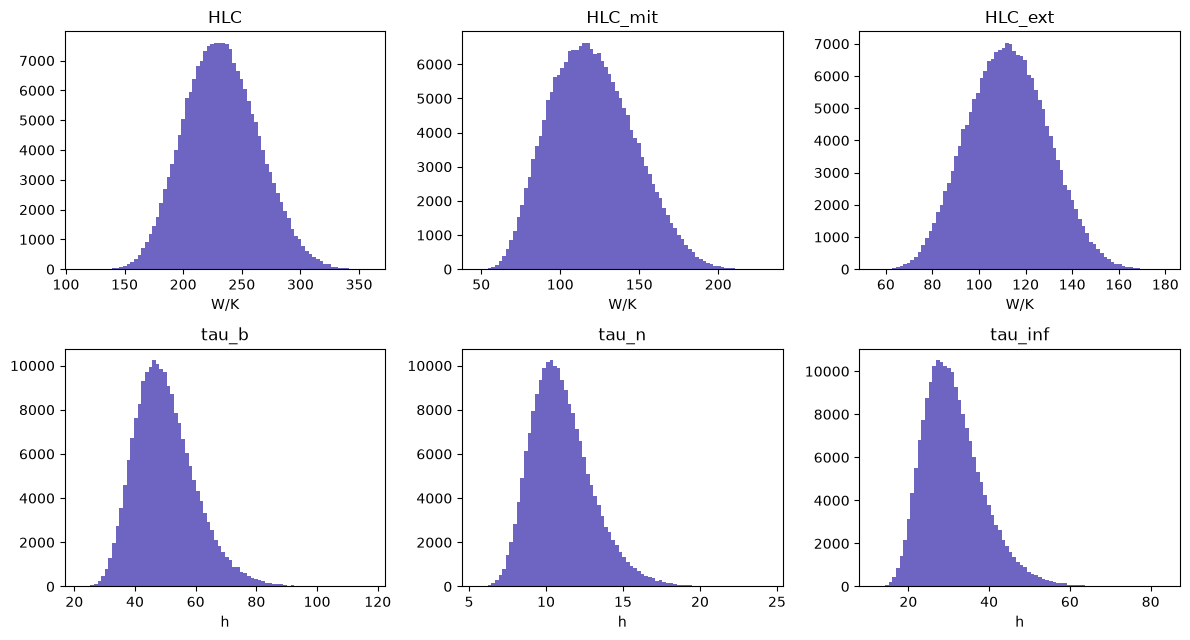

In [31]:
plot_target_distributions(Y, LABELS);

> **Interprétation : distributions des indicateurs**
>
> - **Famille HLC : distributions symétriques, quasi gaussiennes.** Les paramètres thermophysiques sont tirés selon des lois uniformes, mais le HLC et ses composantes sont des **sommes** de nombreuses contributions indépendantes (parois, planchers, ponts thermiques). Par le théorème central limite, leur distribution tend vers une loi normale. Cela explique aussi la dispersion relative réduite du HLC (environ 13 %) par rapport à la plage de tirage des paramètres (±60 %).
> - **Famille CDT : distributions asymétriques à queue droite**, proches d'une loi log-normale. Une constante de temps est un **rapport** de type $\tau \sim C/H$ entre une capacité et une conductance : quand la conductance est faible, $\tau$ augmente fortement, d'où la queue de distribution.
> - **Conséquence pour la modélisation** : les composantes de Hb sont prédites en échelle linéaire (divisées par le HLC moyen), tandis que les $\tau$ sont prédites en **échelle logarithmique**. Cela symétrise leur distribution, garantit la positivité des prédictions et fait porter la perte sur l'erreur relative, plus pertinente pour des grandeurs à forte dynamique.

### 3.3 Corrélations entre indicateurs

**Objectif.** Mesurer les dépendances entre les six indicateurs, pour deux raisons :
1. **Choix d'architecture** : si les indicateurs partagent une information commune, un **modèle multi-tâches** à tronc partagé est pertinent, chaque tâche pouvant bénéficier de l'apprentissage des autres.
2. **Identifiabilité** : des indicateurs fortement corrélés peuvent s'appuyer les uns sur les autres. À l'inverse, des indicateurs indépendants devront chacun être retrouvés à partir d'une information propre dans les signaux.

**Méthode.** On utilise la corrélation de **Spearman**, fondée sur les rangs. Elle détecte toute relation monotone, même non linéaire (comme $\tau \sim C/H$), et elle est peu sensible aux valeurs extrêmes des queues de distribution.

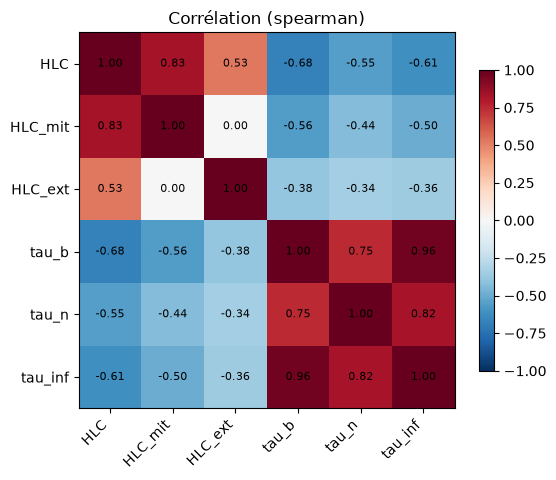

In [10]:
plot_correlation_matrix(Y, LABELS, method="spearman");

> **Interprétation : corrélations entre indicateurs (Spearman)**
>
> - **$\text{HLC}_{mit}$ et $\text{HLC}_{ext}$ sont indépendants ($\rho = 0{,}00$).** Ils dépendent de parois distinctes dont les paramètres sont tirés indépendamment. Puisque $\text{HLC} = \text{HLC}_{mit} + \text{HLC}_{ext}$ avec deux termes indépendants, la corrélation de chaque composante avec le HLC vaut $\sigma_i / \sqrt{\sigma_{mit}^2 + \sigma_{ext}^2}$, soit 0,84 pour $\text{HLC}_{mit}$ et 0,55 pour $\text{HLC}_{ext}$. Ces valeurs correspondent aux 0,83 et 0,53 observés : le HLC est davantage piloté par sa composante mitoyenne, qui est la plus dispersée.
> - **Les constantes de temps sont anticorrélées au HLC** ($\rho$ de −0,55 à −0,68), conformément à $\tau \sim C/H$ : un bâtiment qui perd vite sa chaleur se décharge vite. La corrélation n'est que partielle car l'inertie $C$ varie indépendamment. Elle est plus forte pour $\tau_b$ (grandeur globale mobilisant toute la masse) que pour $\tau_n$ (sensible surtout aux couches superficielles des parois).
> - **$\tau_b$ et $\tau_\infty$ sont quasi redondantes ($\rho = 0{,}96$)** : toutes deux caractérisent le stockage dans toute l'épaisseur des parois. $\tau_n$ s'en distingue davantage (0,75 et 0,82), car elle ne dépend que de la profondeur de pénétration atteinte en 8 h.
>
> **Conséquences pour la modélisation :**
> 1. Les indicateurs partagent une information commune (conductances et capacités du bâti), ce qui justifie un **modèle multi-tâches à tronc partagé**. En particulier, $\tau_b$, difficilement observable sur 8 h, peut tirer parti de sa forte corrélation avec $\tau_\infty$.
> 2. L'indépendance de $\text{HLC}_{mit}$ et $\text{HLC}_{ext}$ pose une **question d'identifiabilité**. Vu depuis $T_{int}$, une perte vers l'extérieur et une perte vers un espace mitoyen ont un effet similaire. Elles ne sont distinguables que si les températures de ces deux environnements évoluent différemment pendant l'essai, et ces températures ne sont pas fournies au modèle. **On s'attend donc à une bonne précision sur le HLC total, mais à une précision dégradée sur sa répartition entre composantes.**

### 3.4 Les signaux d'entrée

**Objectif.** Décrire les deux séries fournies au modèle, la sollicitation $U(t)$ et la température intérieure $T_{int}(t)$, afin de comprendre ce qu'elles contiennent et de repérer d'éventuels cas particuliers.

**Démarche.**
1. **Nature des excitations** : on vérifie, à partir de la forme des signaux, que toutes les excitations sont bien des PRBS, comme l'indiquent les paramètres du générateur (section 3.1 ter).
2. **Exemples de réponses** : on trace quelques couples $(U(t), T_{int}(t))$ choisis pour couvrir toute la plage de $t_{min}$, des créneaux très courts aux créneaux longs. On y observe comment le bâtiment réagit à l'allumage et à l'extinction du chauffage.
3. **Descripteurs agrégés** : pour chaque simulation, on calcule des grandeurs simples (part des pas à 0 ou à $P_{max}$, énergie injectée, puissance maximale, température initiale) et on examine leurs distributions.

**Ce que l'on cherche** : la signature physique de la réponse (échelles de temps, inertie, état initial) et la diversité réelle des excitations, notamment les cas dégénérés comme les simulations sans chauffe, qui conditionneront la difficulté de la prédiction.

kind
PRBS    1.0
Name: part des simulations, dtype: float64


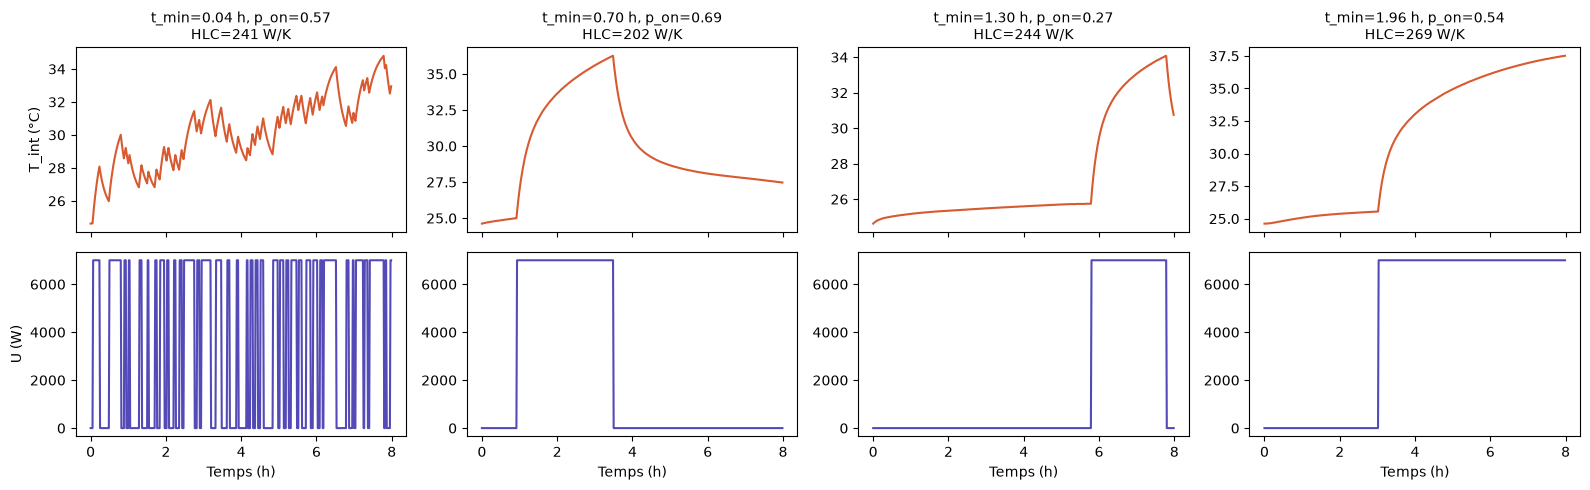

In [32]:
exc = excitation_descriptors(data.excitation.numpy(), data.dt_minutes)
tmp = temperature_descriptors(data.temperature.numpy())
print(exc["kind"].value_counts(normalize=True).rename("part des simulations"))

# Un exemple par quartile de t_min : des créneaux très courts aux créneaux longs
t_min = SOL["prbs_min_duration_hours"].to_numpy()
p_on = SOL["prbs_probability_on"].to_numpy()
examples = [int(np.argmin(np.abs(t_min - q))) for q in np.quantile(t_min, [0.02, 0.35, 0.65, 0.98])]
titles = [f"t_min={t_min[i]:.2f} h, p_on={p_on[i]:.2f}\nHLC={Y[i, 0]:.0f} W/K" for i in examples]
plot_sample_series(data.temperature[examples].numpy(), data.excitation[examples].numpy(),
                   data.dt_minutes, titles);

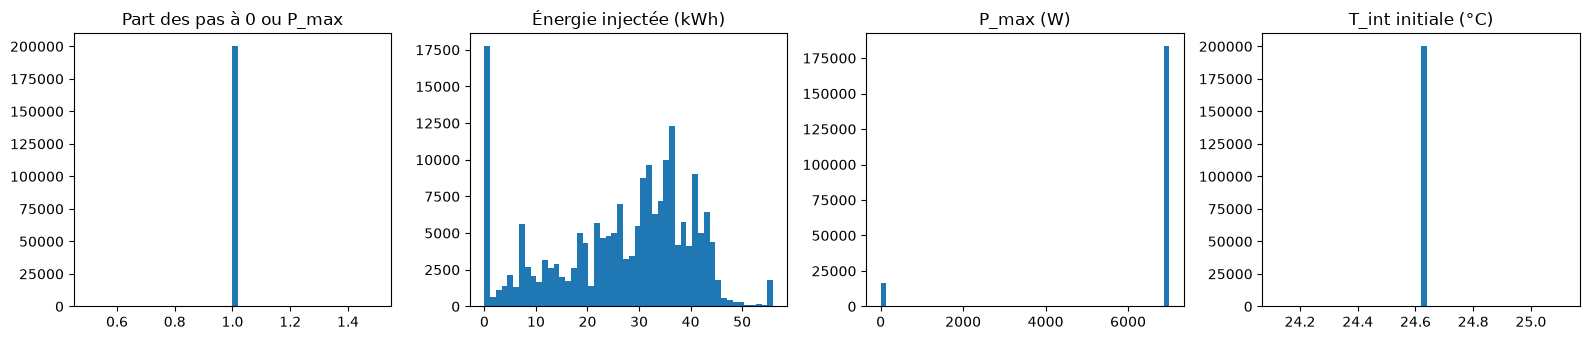

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
axes[0].hist(exc["frac_extreme"], bins=50); axes[0].set_title("Part des pas à 0 ou P_max")
axes[1].hist(exc["energy_kwh"], bins=50); axes[1].set_title("Énergie injectée (kWh)")
axes[2].hist(exc["p_max"], bins=50); axes[2].set_title("P_max (W)")
axes[3].hist(tmp["t_initial"], bins=50); axes[3].set_title("T_int initiale (°C)")
fig.tight_layout()

In [34]:
# Classement des simulations selon le régime d'excitation
regime = np.select(
    [exc["energy_kwh"] == 0, exc["duty_cycle"] == 1],
    ["aucune chauffe", "chauffe continue"],
    default="PRBS (commutations)",
)
REGIME = pd.Series(regime, name="régime")
display(REGIME.value_counts().to_frame("simulations")
        .assign(part=lambda d: (100 * d["simulations"] / len(REGIME)).round(1)))

# Les indicateurs ont-ils la même distribution dans chaque régime ? (ils devraient : tirages indépendants)
pd.DataFrame(Y, columns=LABELS).groupby(regime).mean().round(2)

,simulations,part
régime,,
PRBS (commutations),181536,90.8
aucune chauffe,16705,8.4
chauffe continue,1759,0.9


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
PRBS (commutations),232.89,120.42,112.47,50.00,11.04,31.23
aucune chauffe,232.56,120.22,112.34,50.05,11.05,31.26
chauffe continue,233.75,120.39,113.36,49.64,10.99,30.95


> **Interprétation : signaux d'entrée et réponses thermiques**
>
> La détection automatique classe 100 % des signaux en PRBS, ce qui confirme l'analyse des paramètres d'excitation. Les courbes de réponse illustrent plusieurs phénomènes physiques que le modèle devra exploiter :
>
> - **Une réponse multi-échelles.** À l'allumage, $T_{int}$ présente une montée rapide (quelques degrés en moins d'une heure), due au chauffage de l'air et des surfaces de faible inertie, suivie d'une montée lente et continue liée à la diffusion de la chaleur dans la masse des parois. C'est la signature d'un système à plusieurs constantes de temps, cohérente avec la solution du modèle d'état (somme d'exponentielles).
> - **Un régime permanent jamais atteint.** Avec $P = 7000$ W et un HLC de 244 W/K, l'écart à l'équilibre serait de $P/\text{HLC} \approx 29$ K. Or la montée observée en 8 h n'en représente qu'une fraction. Le HLC ne peut donc pas être lu directement sur l'écart final : il doit être **inféré de la forme du régime transitoire**. C'est précisément ce qui motive l'approche par apprentissage plutôt qu'un bilan statique.
> - **L'effet mémoire de l'inertie.** À l'extinction, la température chute rapidement puis se stabilise nettement au-dessus de sa valeur initiale : la chaleur stockée dans les parois est restituée lentement. Ce comportement est gouverné par les constantes de temps.
> - **Un état initial hors équilibre.** Avant toute sollicitation, $T_{int}$ dérive déjà légèrement. Le bâtiment n'est pas à l'équilibre en début de simulation, conformément à la randomisation de l'état initial. Le modèle doit distinguer cette évolution libre de la réponse à l'excitation. C'est l'une des raisons d'ajouter en entrée le canal $\Delta T_{int} = T_{int} - T_{int}(0)$.
> - **Une diversité des excitations.** Selon $t_{min}$, le signal comporte quelques créneaux longs, qui sollicitent la masse des parois, ou de nombreuses commutations rapides, qui sollicitent surtout l'air et les surfaces. Cette diversité des contenus fréquentiels conditionne l'information disponible sur chaque indicateur.


### 3.5 Lien entre entrées et cibles

**Objectif.** Vérifier que les séries d'entrée contiennent bien l'information nécessaire pour prédire les indicateurs, et identifier ce qui pourrait la masquer.

**Principe physique.** En régime permanent, une puissance $P$ injectée dans le bâtiment produit un écart de température $\Delta T = P / \text{HLC}$ : à puissance égale, un bâtiment plus déperditif s'échauffe moins. Sur une fenêtre de 8 h, ce régime n'est jamais atteint, mais on s'attend à ce que la montée de $T_{int}$ reste liée au HLC.

**Démarche.**
1. **Corrélations simples** : on calcule la corrélation de Spearman entre des descripteurs agrégés des signaux et chaque indicateur. Pour l'excitation : énergie injectée, taux de chauffe, nombre de commutations. Pour la réponse : montée maximale, dérive finale, écart-type de $T_{int}$.
2. **Montée normalisée par l'énergie** : on trace le rapport $\Delta T_{max} / E$ en fonction du HLC, en colorant chaque simulation par son énergie injectée. Les simulations **sans chauffe** ($E = 0$, rapport non défini) sont exclues de cette analyse.
3. **Corrélation à énergie comparable** : pour neutraliser l'effet de l'excitation, on calcule la corrélation entre la montée et le HLC **au sein de chaque décile d'énergie injectée**.

Simulations sans chauffe exclues : 16,705 (8.4 %)


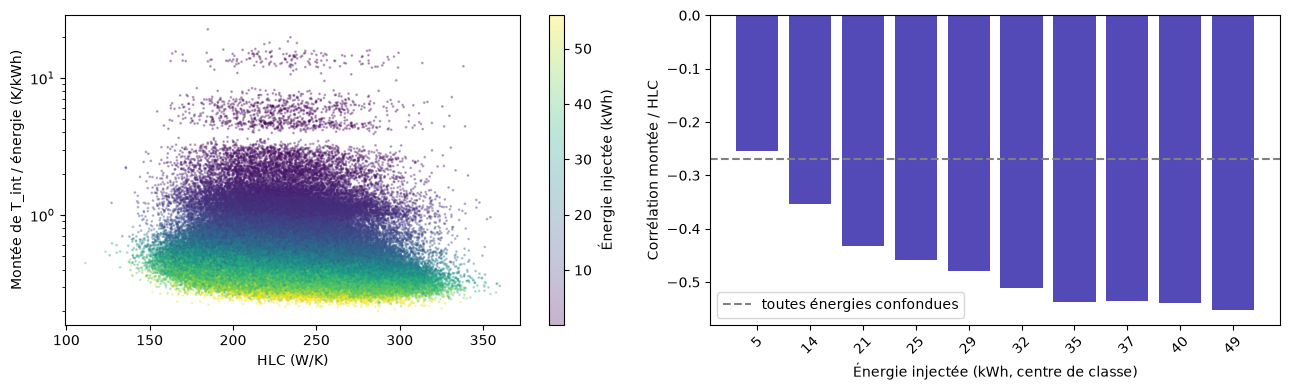

In [35]:
heated = (exc["energy_kwh"] > 0).to_numpy()
print(f"Simulations sans chauffe exclues : {(~heated).sum():,} ({100 * (~heated).mean():.1f} %)")
proxy = (tmp["rise"] / exc["energy_kwh"]).to_numpy()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sc = axes[0].scatter(Y[heated, 0], proxy[heated], c=exc["energy_kwh"][heated],
                     s=1, alpha=0.3, cmap="viridis")
axes[0].set_yscale("log")
axes[0].set_xlabel("HLC (W/K)"); axes[0].set_ylabel("Montée de T_int / énergie (K/kWh)")
fig.colorbar(sc, ax=axes[0], label="Énergie injectée (kWh)")

# Corrélation montée / HLC à énergie comparable (par décile d'énergie)
d = pd.DataFrame({"rise": tmp["rise"][heated].to_numpy(), "HLC": Y[heated, 0],
                  "energie": exc["energy_kwh"][heated].to_numpy()})
d["classe"] = pd.qcut(d["energie"], 10, duplicates="drop")
within = d.groupby("classe", observed=True).apply(
    lambda g: g["rise"].corr(g["HLC"], method="spearman"))
axes[1].bar(range(len(within)), within.to_numpy(), color="#534AB7")
axes[1].set_xticks(range(len(within)), [f"{iv.mid:.0f}" for iv in within.index], rotation=45)
axes[1].set_xlabel("Énergie injectée (kWh, centre de classe)")
axes[1].set_ylabel("Corrélation montée / HLC")
axes[1].axhline(-0.27, ls="--", color="gray", label="toutes énergies confondues")
axes[1].legend()
fig.tight_layout()

> **Interprétation**
>
> - **Pas de fuite d'information.** Les descripteurs de l'excitation (énergie, taux de chauffe, commutations) ont une corrélation nulle avec tous les indicateurs : excitation et bâtiment sont tirés indépendamment. Le modèle devra donc exploiter la **réponse** $T_{int}$ du bâtiment, et non la forme du signal $U$.
>
> - **Un effet du HLC masqué par l'excitation.** La montée de température est corrélée négativement au HLC, comme attendu (un bâtiment plus déperditif s'échauffe moins), mais faiblement ($\rho = -0{,}27$). Le graphique de gauche montre pourquoi : le rapport montée / énergie dépend d'abord de **l'énergie injectée** (stratification des couleurs), et peu du HLC.
>
> - **À énergie comparable, la relation se renforce.** Par décile d'énergie (graphique de droite), la corrélation passe de −0,25 (≈ 5 kWh) à **−0,55** (≈ 49 kWh). Plus on chauffe, plus la réponse forcée se détache de l'évolution libre du bâtiment et renseigne sur ses déperditions. **C'est l'excitation qui rend le HLC identifiable.**
>
> - **Un modèle séquentiel est nécessaire.** Même à énergie égale, la corrélation reste partielle : la montée dépend aussi de l'inertie, du moment de l'injection et de l'état initial. Seule la **forme complète** des courbes permet de séparer ces effets, ce qui justifie le CNN-GRU.
>
> - **$\tau_b$ peu visible en 8 h.** Aucun descripteur simple n'est corrélé à $\tau_b$ ($\rho \approx 0$), ce qui est cohérent avec une valeur moyenne de 50 h, très supérieure à la durée de la fenêtre.
>
> **Attentes** : une erreur plus faible pour les simulations fortement chauffées, et plus forte pour les 8,4 % de simulations sans chauffe (analysé par segment dans l'annexe A2).

### 3.6 Motifs d'excitation partagés

La graine PRBS est commune à toutes les simulations (`prbs_seed = 42`) et la puissance est constante ($P_{max} = 7000$ W). Des paramètres $(t_{min}, p_{on})$ proches peuvent donc produire **exactement le même signal** $U(t)$. On regroupe les simulations dont le signal est strictement identique sur les 480 pas de temps, puis on mesure la part des simulations de validation et de test dont le motif d'excitation apparaît déjà dans le jeu d'entraînement.

In [36]:
u_groups = excitation_groups(data.excitation.numpy())
print(f"{len(np.unique(u_groups)):,} motifs U distincts pour {len(data):,} simulations")

eda_splits = make_splits(len(data), DATA_CFG.val_frac, DATA_CFG.test_frac, DATA_CFG.seed)
group_split_overlap(u_groups, {k: v.numpy() for k, v in eda_splits.items()}).to_frame("part")

2,625 motifs U distincts pour 200,000 simulations


,part
val : motif U déjà vu au train,0.998
test : motif U déjà vu au train,0.998


> **Interprétation**
>
> - **Des motifs d'excitation massivement partagés.** Les 200 000 simulations ne comportent que    **2 625 signaux $U(t)$ distincts**, soit en moyenne environ 76 simulations par motif. Avec un découpage aléatoire, **99,8 %** des simulations de validation et de test ont un signal strictement identique à celui d'au moins une simulation d'entraînement. C'est la conséquence directe de la graine PRBS commune et de la puissance constante.
>
> - **Pas de fuite d'information.** Deux simulations partageant le même $U(t)$ correspondent à des bâtiments différents, et $U$ est indépendant des indicateurs (section 3.5). Connaître le signal ne renseigne donc pas sur la cible : le modèle doit toujours exploiter la réponse $T_{int}$ pour identifier le bâtiment.
>
> - **Une évaluation partielle.** Le découpage aléatoire mesure la capacité du modèle à **identifier un bâtiment inconnu soumis à une excitation déjà rencontrée**. C'est la situation de la phase sur site de la méthode de référence, où un même signal est appliqué à une population de bâtiments. Il ne mesure pas la généralisation à une **excitation inédite**, qui est pourtant le cas réel, puisque l'excitation est optimisée pour chaque bâtiment et chaque essai.
>
> - **Conséquence méthodologique.** Les performances obtenues avec le découpage aléatoire pourraient être optimistes. La modélisation utilise donc un **découpage par motif d'excitation** (`modelisation.ipynb`, section 4.4) : chaque motif appartient entièrement au train, à la validation ou au test, et aucun signal du test n'apparaît à l'entraînement. Le score mesure ainsi la généralisation à une **excitation inédite**.

### 3.8 Richesse des excitations

Un signal d'excitation est d'autant plus informatif qu'il sollicite le bâtiment à plusieurs échelles de temps : des commutations fréquentes excitent l'air et les surfaces, des créneaux longs la masse des parois. On caractérise chaque signal par son **nombre de fronts** (allumages et extinctions) et par **l'instant du premier allumage**, qui détermine la durée de la fenêtre réellement exploitable.

,part des simulations,montée médiane de T_int (K),énergie médiane (kWh)
2 à 4 fronts,0.441,12.09,26.483
un seul front (échelon),0.301,13.49,36.750
5 fronts et plus,0.174,11.38,28.350
aucune chauffe,0.084,1.27,0.000


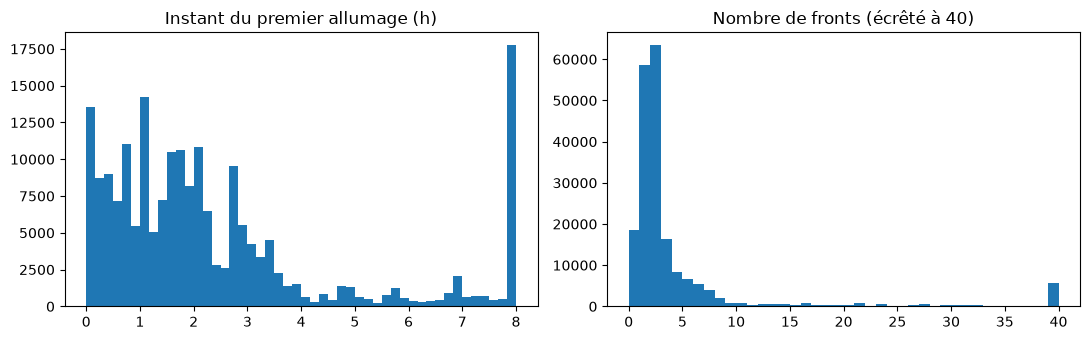

In [37]:
richness = excitation_richness(data.excitation.numpy(), data.dt_minutes)
category = richness["categorie"].to_numpy()
summary = pd.DataFrame({
    "part des simulations": richness["categorie"].value_counts(normalize=True),
    "montée médiane de T_int (K)": tmp["rise"].groupby(category).median(),
    "énergie médiane (kWh)": exc["energy_kwh"].groupby(category).median(),
})
display(summary.sort_values("part des simulations", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(richness["first_on_h"], bins=48)
axes[0].set_title("Instant du premier allumage (h)")
axes[1].hist(richness["n_switches"].clip(upper=40), bins=40)
axes[1].set_title("Nombre de fronts (écrêté à 40)")
fig.tight_layout()

> **Interprétation**
>
> - **Des excitations majoritairement pauvres.** Seules **17 %** des simulations comportent 5 fronts ou plus. **30 %** se réduisent à un **échelon unique** (un seul allumage), et 44 % ne comptent que 2 à 4 fronts. Avec des créneaux de durée $[t_{min}, 2\,t_{min}]$ pouvant atteindre 4 h, la fenêtre de 8 h ne contient souvent que 2 ou 3 créneaux. Le pic à 40 fronts correspond aux faibles valeurs de $t_{min}$, pour lesquelles le signal commute presque à chaque pas.
> - **Une fenêtre utile souvent réduite.** Le premier allumage intervient fréquemment après 1 à 3 h. Le pic à 8 h correspond aux 8,4 % de simulations sans chauffe. Avant le premier allumage, seule l'évolution libre est observable : la durée de réponse forcée effectivement disponible est donc souvent bien inférieure à 8 h.
> - **L'amplitude de l'évolution libre.** Sans chauffe, $T_{int}$ monte tout de même de **1,3 K** en médiane, sous l'effet de l'état initial hors équilibre des parois. C'est l'ordre de grandeur de la perturbation dont le modèle doit séparer la réponse à l'excitation, soit environ 10 % de la montée observée en présence de chauffe (11 à 13 K).
> - **Une amplitude de réponse comparable entre catégories.** La montée médiane varie peu (de 11,4 à 13,5 K). L'échelon produit la montée la plus forte, car il injecte le plus d'énergie (36,8 kWh). Le nombre de fronts modifie surtout la **forme** de la réponse, donc son contenu en échelles de temps, plutôt que son amplitude.
>
> **Hypothèses pour l'évaluation (analyse par segment, annexe A2).** Un premier allumage tardif devrait dégrader la précision, puisque la réponse forcée est plus courte. Le nombre de fronts devrait influencer différemment les indicateurs : les commutations fréquentes renseignent sur la dynamique rapide (utile pour $\tau_n$), les créneaux longs sur la pénétration dans les parois (utile pour $\tau_\infty$ et $\tau_b$).

### 3.9 Part de la réponse attribuable au bâtiment

On décompose, à chaque instant $t$, la variance de $T_{int}(t)$ entre simulations en deux parts, à l'aide des groupes de simulations partageant exactement le même signal $U(t)$ (section 3.7) :
- la **variance inter-groupes**, due aux différences d'excitation ;
- la **variance intra-groupe**, due aux différences de bâtiment (et d'état initial des parois), à excitation identique.

Le rapport de corrélation $\eta^2 = \text{variance inter-groupes} / \text{variance totale}$ mesure la part de la variabilité de $T_{int}$ expliquée par l'excitation ; $1 - \eta^2$ est la part attribuable au bâtiment, c'est-à-dire **l'information exploitable** pour prédire les indicateurs.

,1.0,2.0,3.0,4.0,5.0,6.0,7.0
η² (motif U),0.984,0.971,0.953,0.94,0.941,0.94,0.942


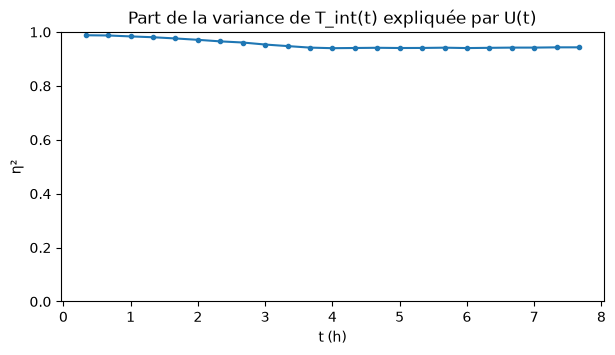

In [17]:
eta2 = variance_share_by_group(data.temperature.numpy(), u_groups, step=20,
                               dt_minutes=data.dt_minutes)
ax = eta2.plot(figsize=(7, 3.5), marker=".")
ax.set_xlabel("t (h)"); ax.set_ylabel("η²"); ax.set_ylim(0, 1)
ax.set_title("Part de la variance de T_int(t) expliquée par U(t)")
eta2.iloc[2::3].round(3).to_frame().T

,1.0,2.0,3.0,4.0,5.0,6.0,7.0
écart-type (K),0.31,0.61,0.85,1.01,1.1,1.14,1.14


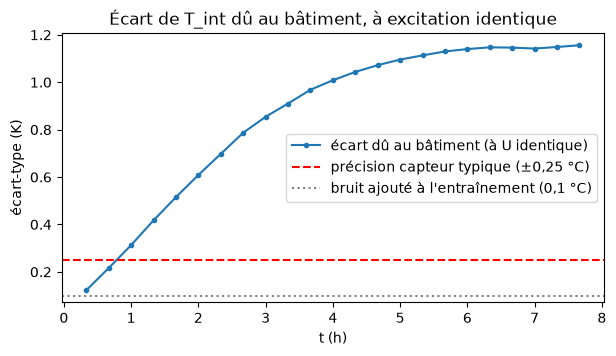

In [38]:
T = data.temperature.numpy()
g = pd.Series(u_groups)
steps = np.arange(20, T.shape[1], 20)
within_std = []
for k in steps:
    s = pd.Series(T[:, k])
    within_std.append(np.sqrt((s - s.groupby(g).transform("mean")).pow(2).mean()))
within_std = pd.Series(within_std, index=steps * data.dt_minutes / 60)

ax = within_std.plot(figsize=(7, 3.5), marker=".", label="écart dû au bâtiment (à U identique)")
ax.axhline(0.25, ls="--", color="red", label="précision capteur typique (±0,25 °C)")
ax.axhline(0.1, ls=":", color="gray", label="bruit ajouté à l'entraînement (0,1 °C)")
ax.set_xlabel("t (h)"); ax.set_ylabel("écart-type (K)"); ax.legend()
ax.set_title("Écart de T_int dû au bâtiment, à excitation identique")
within_std.iloc[2::3].round(2).to_frame("écart-type (K)").T

> **Interprétation**
>
> - **L'excitation domine la réponse.** Le motif d'excitation explique **94 à 98 %** de la variance de $T_{int}(t)$ entre simulations. La part attribuable au bâtiment, seule porteuse d'information sur les indicateurs, ne représente que **2 à 6 %**. Le modèle doit donc extraire un signal faible, superposé à une réponse très majoritairement déterminée par l'excitation. Cela confirme quantitativement le constat de la section 3.5 et rend indispensable la présence de $U(t)$ en entrée : sans elle, l'effet de l'excitation ne pourrait pas être séparé de celui du bâtiment.
> - **Une information qui s'accumule puis plafonne.** La part du bâtiment croît de 1,6 % à 1 h à environ 6 % à partir de 4 h, puis se stabilise. En début d'essai, les bâtiments n'ont pas encore eu le temps de se différencier ; leurs différences de déperditions et d'inertie se manifestent progressivement. Les premières heures sont donc peu informatives, et la précision devrait se dégrader nettement pour des fenêtres plus courtes qu'environ 4 h, ce qui est cohérent avec la dépendance à la durée d'essai observée dans la méthode de référence.
> - **Amplitude absolue du signal utile.** À excitation identique, l'écart-type de $T_{int}$ dû au bâtiment croît de 0,12 K à 0,3 h jusqu'à environ **1,0 K à 4 h**, puis plafonne vers **1,14 K**. Il dépasse la précision typique d'un capteur réel (±0,25 °C) dès environ **45 minutes**, et en représente **4 à 5 fois** la valeur à partir de 4 h. Les indicateurs sont donc identifiables en conditions réelles, à l'exception de la première heure, pendant laquelle l'écart entre bâtiments reste du même ordre que le bruit de mesure.
>
>   Trois nuances s'imposent :
>   1. le modèle exploite les 480 points de la série et non une mesure ponctuelle : un bruit aléatoire, indépendant d'un pas à l'autre, se moyenne partiellement, et le rapport signal sur bruit effectif est supérieur à celui indiqué ici ;
>   2. un **biais systématique** du capteur ne se moyenne pas, et n'est pas représenté par le bruit gaussien ajouté à l'entraînement ;
>   3. cet écart inclut l'effet de l'état initial des parois, qui varie d'une simulation à l'autre : la part strictement liée aux indicateurs est donc légèrement inférieure.
>
> - **Conséquence pour l'évaluation.** Le bruit ajouté à l'entraînement ($\sigma_T = 0{,}1$ °C) est inférieur à la précision typique d'un capteur. La robustesse du modèle est donc testée dans `modelisation.ipynb`, section 6.1, pour des niveaux de bruit allant jusqu'à 0,25 °C et au-delà.

### 3.10 Expérience contrôlée : quand $T_{int}$ renseigne-t-elle sur chaque indicateur ?

Pour isoler l'effet du bâtiment de celui de l'excitation, on sélectionne deux groupes de simulations ayant reçu **exactement le même signal** $U(t)$ :
- un groupe **sans chauffe** ($U = 0$ sur 8 h) ;
- un groupe soumis à un **échelon** de chauffe (allumage unique vers 2,75 h).

Au sein de chaque groupe, l'excitation est identique : les différences de $T_{int}$ ne proviennent que du bâtiment et de son état initial. On calcule, à chaque instant $t$, la corrélation de Spearman (en valeur absolue) entre $T_{int}(t)$ et chaque indicateur. Le profil obtenu indique **à quel moment** la réponse thermique porte de l'information sur chaque indicateur.

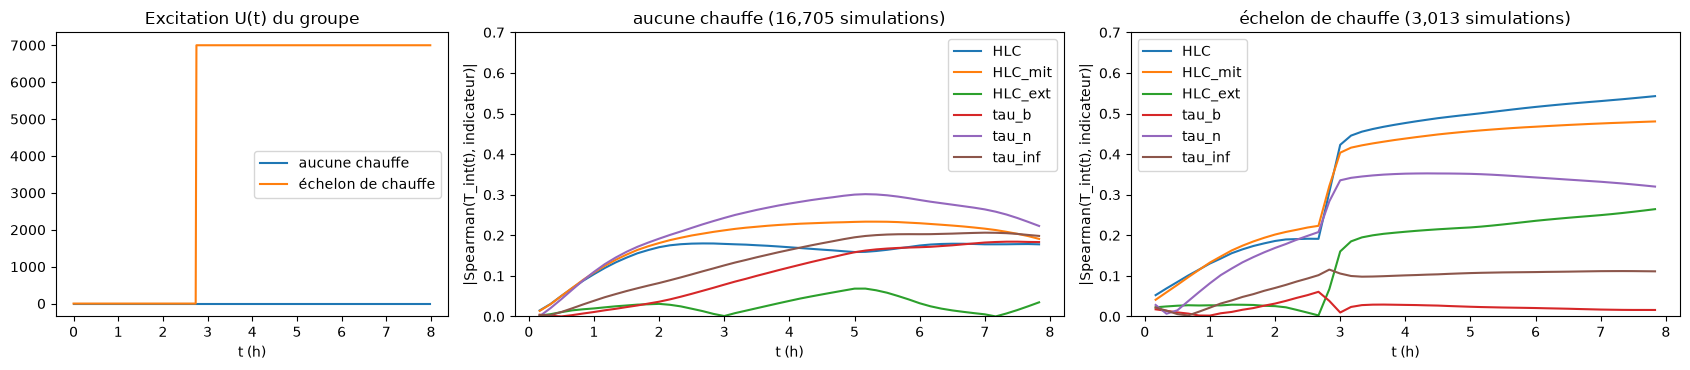

In [18]:
T_np = data.temperature.numpy()
t_h = np.arange(data.n_steps) * data.dt_minutes / 60
step_mask = (richness["categorie"] == "un seul front (échelon)").to_numpy()
controlled = {
    "aucune chauffe": u_groups[np.argmax(exc["energy_kwh"].to_numpy() == 0)],
    "échelon de chauffe": np.bincount(u_groups[step_mask]).argmax(),
}
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8), gridspec_kw={"width_ratios": [1, 1.4, 1.4]})
for name, g in controlled.items():
    axes[0].plot(t_h, data.excitation[np.argmax(u_groups == g)].numpy(), label=name)
axes[0].set_title("Excitation U(t) du groupe"); axes[0].set_xlabel("t (h)"); axes[0].legend()
for ax, (name, g) in zip(axes[1:], controlled.items()):
    m = u_groups == g
    prof = temporal_information_profile(T_np[m], Y[m], LABELS, step=10,
                                        dt_minutes=data.dt_minutes)
    prof.plot(ax=ax)
    ax.set_title(f"{name} ({m.sum():,} simulations)"); ax.set_xlabel("t (h)")
    ax.set_ylabel("|Spearman(T_int(t), indicateur)|"); ax.set_ylim(0, 0.7)
fig.tight_layout()

> **Interprétation**
>
> - **Sans chauffe, une information faible mais non nulle.** Les corrélations atteignent 0,2 à 0,3 pour $\tau_n$, $\text{HLC}_{mit}$ et $\tau_\infty$ : l'évolution libre du bâtiment depuis un état initial hors équilibre dépend elle aussi de ses déperditions et de son inertie. Les simulations sans chauffe sont donc **faiblement informatives**, mais pas dépourvues d'information. $\text{HLC}_{ext}$ y reste en revanche quasi invisible ($|\rho| < 0{,}07$).
> - **L'excitation révèle immédiatement les déperditions.** Dans le groupe soumis à un échelon, les profils sont identiques à ceux du groupe sans chauffe jusqu'à l'allumage, ce qui confirme la cohérence de l'analyse. Au moment de l'allumage, la corrélation avec le HLC **double brutalement** (de 0,19 à 0,42), puis continue de croître jusqu'à 0,54 à 8 h. C'est l'illustration directe du principe de la méthode : **c'est la sollicitation qui rend le HLC identifiable**, et l'information s'accumule avec la durée de chauffe. Le même saut s'observe pour $\text{HLC}_{mit}$ (jusqu'à 0,48) et, plus modestement, pour $\text{HLC}_{ext}$ (jusqu'à 0,27), moins bien renseigné car moins dispersé (section 3.3).
> - **$\tau_n$ : une information concentrée juste après l'allumage.** Sa corrélation atteint environ 0,35 peu après l'allumage, puis décroît légèrement. $\tau_n$ caractérise la dynamique rapide (air et couches superficielles), visible dans les premières heures de la réponse forcée.
> - **$\tau_b$ : hors de portée de la fenêtre.** La chauffe n'apporte aucune information sur $\tau_b$, dont la corrélation tombe même à environ 0,02 après l'allumage ; $\tau_\infty$ plafonne vers 0,1. La réponse forcée est dominée par les déperditions et la dynamique rapide, tandis que la décharge lente de l'ensemble du bâti ($\tau_b \approx 50$ h) ne se manifeste pas en 8 h. **$\tau_b$ devrait être l'indicateur le moins bien prédit**, sa prédiction reposant probablement sur sa corrélation avec les autres indicateurs (notamment $\tau_\infty$, $\rho = 0{,}96$).
> - **Une borne inférieure.** Ces corrélations portent sur un seul instant à la fois. Le modèle exploite conjointement l'ensemble des 480 pas de temps et les relations entre eux : l'information réellement disponible est donc supérieure à celle indiquée par ces profils.
>
> **Hiérarchie de difficulté attendue :** HLC et $\text{HLC}_{mit}$ (les mieux renseignés), puis $\tau_n$, puis $\text{HLC}_{ext}$ et $\tau_\infty$, et enfin $\tau_b$.

### 3.11 Analyse fréquentielle

On compare le contenu fréquentiel moyen de l'excitation $U(t)$ et de la réponse $T_{int}(t)$ (densité spectrale de puissance, sur 20 000 simulations), et on le situe par rapport à deux références :
- la **résolution de la fenêtre** $1/D = 0{,}125$ cycle/h ($D = 8$ h), c'est-à-dire la variation la plus lente observable sur la durée de l'essai ;
- les **fréquences caractéristiques** des constantes de temps, $f_c = 1/(2\pi\tau)$, calculées pour leurs valeurs médianes. Cette formule est celle d'un système du premier ordre : elle donne un ordre de grandeur pour un système multi-modes.

,U,T_int
part de puissance > 0.5 cycle/h,0.241,0.037
part de puissance > 1 cycle/h,0.153,0.009
part de puissance > 2 cycle/h,0.096,0.002


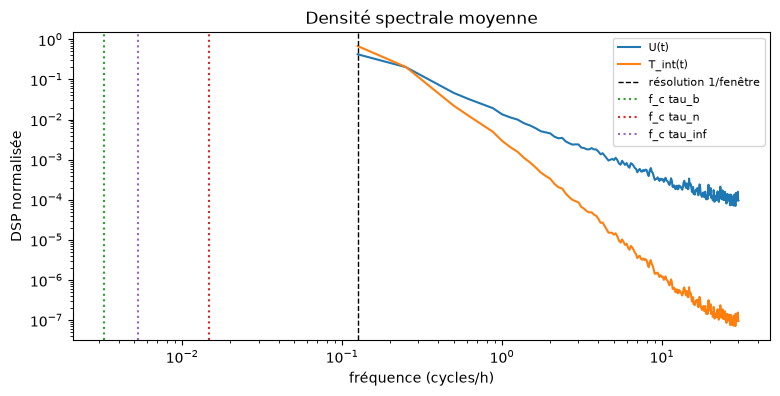

In [19]:
sub = np.random.default_rng(0).choice(len(data), 20_000, replace=False)
f, psd_u = mean_power_spectrum(data.excitation.numpy()[sub], data.dt_minutes)
_, psd_t = mean_power_spectrum(T_np[sub], data.dt_minutes)
duration_h = data.n_steps * data.dt_minutes / 60

fig, ax = plt.subplots(figsize=(9, 4))
ax.loglog(f, psd_u, label="U(t)"); ax.loglog(f, psd_t, label="T_int(t)")
ax.axvline(1 / duration_h, color="k", ls="--", lw=1, label="résolution 1/fenêtre")
for j, c in zip(range(3, 6), ["C2", "C3", "C4"]):
    ax.axvline(1 / (2 * np.pi * np.median(Y[:, j])), color=c, ls=":", label=f"f_c {LABELS[j]}")
ax.set_xlabel("fréquence (cycles/h)"); ax.set_ylabel("DSP normalisée"); ax.legend(fontsize=8)
ax.set_title("Densité spectrale moyenne")

pd.DataFrame({"U": [psd_u[f > s].sum() for s in (0.5, 1, 2)],
              "T_int": [psd_t[f > s].sum() for s in (0.5, 1, 2)]},
             index=[f"part de puissance > {s} cycle/h" for s in (0.5, 1, 2)]).round(3)

> **Interprétation**
>
> - **Le bâtiment se comporte comme un filtre passe-bas.** L'excitation PRBS contient une part importante de hautes fréquences (24 % de sa puissance au-delà de 0,5 cycle/h), liée à ses commutations brusques. La réponse $T_{int}$ n'en conserve que 3,7 %, et 0,2 % au-delà de 2 cycles/h : l'inertie de l'air et des parois atténue fortement les variations rapides de la sollicitation. C'est la signature attendue d'un système thermique capacitif.
> - **Les constantes de temps sont hors de la bande observable.** Les fréquences caractéristiques des trois constantes de temps (de 0,003 à 0,015 cycle/h) sont **8 à 40 fois inférieures** à la résolution de la fenêtre. Aucun cycle complet de ces dynamiques n'est observable en 8 h : les constantes de temps ne peuvent pas être lues directement dans la réponse, mais doivent être **inférées de la forme de son régime transitoire initial**. L'écart est maximal pour $\tau_b$, ce qui confirme, sous l'angle fréquentiel, la conclusion de la section 3.10.
> - **Conséquence pratique : un sous-échantillonnage possible.** $T_{int}$ ne contient quasiment pas de puissance au-delà de 2 cycles/h. Un pas de 5 minutes (fréquence de Nyquist de 6 cycles/h) suffirait a priori à la représenter, et réduirait la longueur des séquences de 480 à 96 pas, ce qui accélère l'entraînement d'un facteur d'environ 5. Une faible puissance n'implique cependant pas une absence d'information : la réponse immédiate aux commutations pourrait renseigner sur $\tau_n$. Ce choix est donc **évalué expérimentalement** (comparaison des pas de 1 et 5 minutes).
> - **Limite.** Les séries, souvent croissantes sur la fenêtre, ne sont pas stationnaires : leur tendance renforce artificiellement la puissance aux basses fréquences (fuite spectrale). La forme précise des spectres est donc indicative ; seul le contraste entre $U$ et $T_{int}$ est interprété.

### 3.12 Structure des courbes de réponse (ACP)

On applique une analyse en composantes principales aux courbes $\Delta T_{int}(t) = T_{int}(t) - T_{int}(0)$ (20 000 simulations), afin d'évaluer leur dimension effective et de vérifier si leurs principales directions de variation portent l'information sur les indicateurs.

,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
CP1,0.14,0.12,0.06,0.01,0.10,0.04
CP2,-0.00,0.00,-0.01,0.01,0.02,0.01
CP3,0.02,0.02,0.01,0.01,0.01,0.01
CP4,0.03,0.02,0.02,-0.02,-0.00,-0.01
CP5,-0.01,-0.01,-0.01,-0.00,-0.01,-0.01
CP6,-0.02,-0.02,-0.01,-0.00,0.00,-0.00
CP7,0.01,0.01,0.01,0.00,0.01,0.00
CP8,-0.03,-0.03,-0.01,0.02,-0.01,0.01
CP9,-0.01,-0.01,-0.00,-0.00,-0.01,-0.01
CP10,0.03,0.02,0.02,-0.01,0.01,-0.00


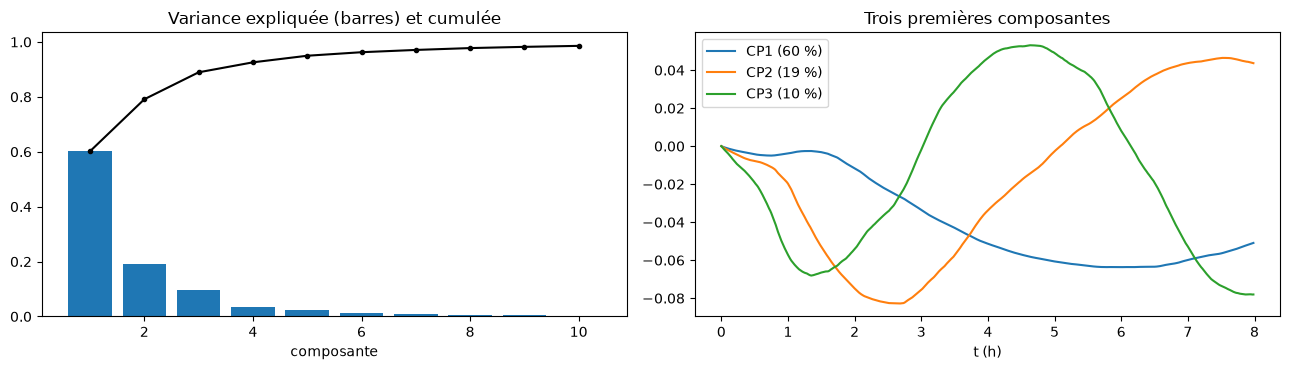

In [20]:
explained, scores, components = curve_svd(T_np[sub] - T_np[sub, :1], k=10)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(range(1, 11), explained); axes[0].plot(range(1, 11), np.cumsum(explained), "k.-")
axes[0].set_xlabel("composante"); axes[0].set_title("Variance expliquée (barres) et cumulée")
for k in range(3):
    axes[1].plot(t_h, components[k], label=f"CP{k + 1} ({100 * explained[k]:.0f} %)")
axes[1].set_xlabel("t (h)"); axes[1].legend(); axes[1].set_title("Trois premières composantes")
fig.tight_layout()
spearman_table(pd.DataFrame(scores, columns=[f"CP{k + 1}" for k in range(10)]),
               Y[sub], LABELS).round(2)

> **Interprétation**
>
> - **Des courbes de faible dimension.** Trois composantes expliquent 89 % de la variance des courbes, et dix environ 98 %. Les réponses thermiques sont lisses, conformément au caractère passe-bas du bâtiment (section 3.11).
> - **Des composantes dominantes non informatives.** Les premières composantes ont la forme de réponses à des créneaux de chauffe placés à différents instants : elles décrivent l'**excitation**, et non le bâtiment. Leur corrélation avec les indicateurs est quasi nulle ($|\rho| \le 0{,}14$). C'est cohérent avec la section 3.9 : l'excitation explique l'essentiel de la variance des courbes, et l'information sur le bâtiment n'en représente que quelques pourcents.
> - **Conséquence pour la modélisation.** Une réduction de dimension **non supervisée** (ACP) conserverait en priorité les directions liées à l'excitation, au risque d'éliminer l'information utile, de faible variance. On écarte donc ce type de prétraitement au profit d'un modèle **supervisé** apprenant directement, à partir des séries complètes $T_{int}(t)$ et $U(t)$, les motifs pertinents pour chaque indicateur.



### 3.14 Structure physique et forme des cibles
On vérifie l'intuition $\tau \sim C/H$ en construisant une **capacité effective** $C_{eff} = \tau_\infty \cdot \text{HLC}$, puis on contrôle l'asymétrie et les valeurs atypiques (z-score robuste médiane/MAD sur le log).

C_eff = tau_inf x HLC : médiane 25.3 MJ/K, P1-P99 [16.3, 37.9]


,HLC,HLC_mit,HLC_ext,tau_b,tau_n,tau_inf
"Spearman(C_eff, ·)",-0.06,-0.03,-0.06,0.71,0.63,0.8


,asymétrie (brut),asymétrie (log),|z robuste| max,part |z| > 5
HLC,0.184,-0.175,5.266,5.000e-06
HLC_mit,0.289,-0.225,3.937,0.000e+00
HLC_ext,0.096,-0.303,4.509,0.000e+00
tau_b,0.711,0.109,4.433,0.000e+00
tau_n,0.759,0.210,4.609,0.000e+00
tau_inf,0.847,0.133,4.328,0.000e+00


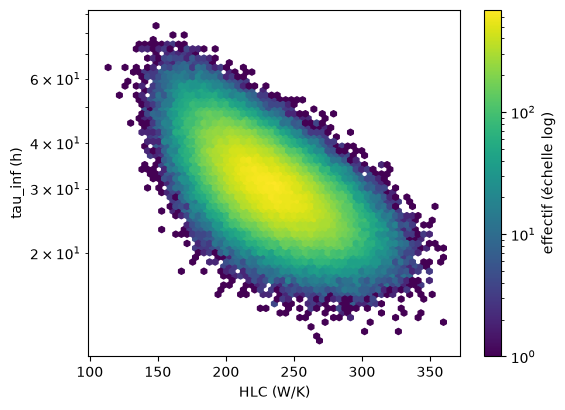

In [22]:
c_eff = Y[:, 5] * Y[:, 0] * 3600 / 1e6  # MJ/K
print(f"C_eff = tau_inf x HLC : médiane {np.median(c_eff):.1f} MJ/K, "
      f"P1-P99 [{np.percentile(c_eff, 1):.1f}, {np.percentile(c_eff, 99):.1f}]")
display(pd.DataFrame(spearman_matrix(c_eff, Y), index=["Spearman(C_eff, ·)"],
                     columns=LABELS).round(2))

fig, ax = plt.subplots(figsize=(6, 4.5))
hb = ax.hexbin(Y[:, 0], Y[:, 5], gridsize=60, bins="log", cmap="viridis", yscale="log")
ax.set_xlabel("HLC (W/K)"); ax.set_ylabel("tau_inf (h)")
fig.colorbar(hb, ax=ax, label="effectif (échelle log)")
robust_outliers(Y, LABELS, threshold=5)

> **Interprétation : structure des cibles**
>
> - $C_{eff}$ (médiane ≈ 25 MJ/K, soit environ 7 kWh/K) est **quasi indépendante du HLC** ($\rho_s = -0{,}06$), mais fortement corrélée aux $\tau$ (0,63 à 0,80). La corrélation négative HLC–$\tau$ (≈ −0,6, section 3.3) est donc **mécanique** : elle découle de $\tau = C/H$ avec $C$ et $H$ tirés indépendamment. Le jeu se décrit par deux grandeurs latentes quasi indépendantes, **déperdition et capacité**. Cela suggère une paramétrisation alternative des têtes : prédire $\log \text{HLC}$ et $\log C_{eff}$, puis en déduire $\log\tau = \log C - \log H$.
> - $\text{HLC}_{mit}$ et $\text{HLC}_{ext}$ sont **non corrélés** ($\rho_s = 0{,}00$) : tirages indépendants. Leur somme donne au HLC une corrélation de 0,83 avec $\text{HLC}_{mit}$, la composante la plus dispersée.
> - **Aucune valeur aberrante** : la part des $|z| > 5$ est nulle, à une simulation près. Les longues queues observées en 3.2 sont celles d'une loi log-normale, et le passage au log ramène l'asymétrie des $\tau$ de 0,7–0,85 à 0,1–0,2. **Aucun filtrage n'est nécessaire**, et la transformation log est validée.



### 3.13 Synthèse de l'EDA : constats et décisions de modélisation

| # | Constat | Section | Décision / action |
|---|---|---|---|
| 1 | Les 4 batchs utilisés sont représentatifs des 20 : écarts de moyenne inférieurs à 0,1 % sur tous les indicateurs (1 000 000 de simulations vérifiées) | 3.1 bis | Travail sur 200 000 simulations ; découpage aléatoire sans stratification par batch |
| 2 | Données propres : aucune valeur manquante, aucun indicateur négatif ou nul, aucune valeur aberrante ($|z|_{robuste} > 5$ pour une seule simulation sur 200 000) ; $T_{int}$ arrondie à 0,01 °C | 3.1, 3.12 | Aucun filtrage |
| 3 | $\text{HLC} = \text{HLC}_{mit} + \text{HLC}_{ext}$ exacte (écart max $3 \cdot 10^{-5}$ W/K, précision float32) ; $\tau_n < \tau_\infty < \tau_b$ dans 100 % des simulations ; $U \ge 0$ | 3.1 | Somme imposée **par construction** ; ordre des $\tau$ vérifié a posteriori (piste : l'imposer) |
| 4 | Excitation 100 % PRBS, $P_{max} = 7000$ W fixe, graine commune ; deux paramètres libres, $t_{min} \sim \mathcal{U}(0, 2)$ h et $p_{on} \sim \mathcal{U}(0{,}2 ;\ 0{,}9)$, avec $t_{max} = 2\,t_{min}$ | 3.1 ter | Analyse des erreurs selon $(t_{min}, p_{on})$ plutôt que selon le type d'excitation |
| 5 | Famille HLC quasi gaussienne (somme de contributions indépendantes) ; $\tau$ asymétriques, ramenées de 0,7–0,85 à 0,1–0,2 d'asymétrie par le log | 3.2, 3.12 | Hb en échelle linéaire, **$\tau$ en échelle logarithmique** |
| 6 | $\text{HLC}_{mit}$ et $\text{HLC}_{ext}$ indépendants ($\rho = 0{,}00$), et d'effet similaire sur $T_{int}$ ; $\text{HLC}_{mit}$ plus dispersé (52 % du HLC) | 3.3 | **Séparation mit / ext attendue difficile** ; erreur analysée par composante |
| 7 | $\tau \approx C_{eff}/\text{HLC}$ avec $C_{eff}$ (≈ 25 MJ/K) indépendante du HLC, ce qui explique entièrement l'anticorrélation $\tau$ / HLC (≈ −0,6) ; $\tau_b$ et $\tau_\infty$ quasi redondantes ($\rho = 0{,}96$) | 3.3, 3.12 | Modèle **multi-tâches à tronc commun** ; piste : têtes $(\log \text{HLC}, \log C_{eff})$ |
| 8 | Excitation indépendante des indicateurs, et régimes d'excitation de même distribution d'indicateurs | 3.4, 3.5 | Aucun raccourci exploitable : le modèle doit lire la réponse $T_{int}$ |
| 9 | 8,4 % de simulations sans chauffe, 0,9 % en chauffe continue ; 30 % à un seul front, 17 % seulement à 5 fronts ou plus ; premier allumage souvent tardif | 3.4, 3.7 | Simulations conservées ; **erreur ventilée par régime et richesse d'excitation** (annexe A2, analyse par segment) |
| 10 | $T_{int}(0) = 24{,}62$ °C pour toutes les simulations : l'état initial aléatoire porte sur les parois | 3.4 | Canal $\Delta T_{int}$ ajouté en entrée, pour isoler la réponse dynamique |
| 11 | Montée de $T_{int}$ liée au HLC ($\rho = -0{,}27$), mais masquée par l'énergie injectée ; à énergie comparable, $\rho$ passe de −0,25 (≈ 5 kWh) à −0,55 (≈ 49 kWh) | 3.5 | **$U$ indispensable en entrée** ; précision attendue meilleure pour les simulations fortement chauffées |
| 12 | 2 625 motifs $U$ pour 200 000 simulations ; 99,8 % des motifs de validation et de test déjà vus à l'entraînement | 3.6 | Évaluation complémentaire **par motif $U$** (généralisation à une excitation inédite) |
| 13 | 94 à 98 % de la variance de $T_{int}$ due à l'excitation ; signal propre au bâtiment ≈ 1,1 K, inférieur au bruit capteur (0,25 °C) avant ≈ 45 min, puis 4 à 5 fois supérieur | 3.8 | Bruit d'entraînement de 0,1 °C **optimiste** ; **robustesse testée jusqu'à 0,25 °C et au-delà** (`modelisation.ipynb`, 6.1) |
| 14 | La chauffe révèle immédiatement le HLC (corrélation doublée à l'allumage), sans informer $\tau_b$ ; information sur $\tau_n$ concentrée juste après l'allumage | 3.9 | Confirme la hiérarchie de difficulté ci-dessous |
| 15 | Bâtiment passe-bas ; fréquences caractéristiques des $\tau$ 8 à 40 fois sous la résolution de la fenêtre ; 0,2 % de la puissance de $T_{int}$ au-delà de 2 cycles/h | 3.10 | $\tau$ inférées de la forme du transitoire ; **sous-échantillonnage à 5 min envisageable** (à valider) |

**Hiérarchie de difficulté attendue** (confrontée aux résultats dans `modelisation.ipynb`, section 5.2) :
HLC ≈ $\text{HLC}_{mit}$ (les mieux renseignés) → $\tau_n$ → $\text{HLC}_{ext}$ → $\tau_\infty$ → $\tau_b$ (hors de portée de la fenêtre de 8 h).

*Hypothèse de travail : le pas de temps d'une minute n'est pas stocké dans les fichiers ; il est déduit de la méthode de référence et de la cohérence avec $t_0 = 8$ h.*

### 3.15 Ce que sont devenues ces décisions pendant la modélisation

| Décision de l'EDA | Mise en œuvre finale (`modelisation.ipynb`) |
|---|---|
| Travail sur 4 batchs (200 000 simulations), représentatifs des 20 | L'EDA reste sur 4 batchs ; le modèle final est entraîné sur **les 20 batchs** (802 242 simulations en train), section 4.4 |
| Découpage aléatoire, évaluation complémentaire par motif $U$ (constat 12) | Le **découpage par motif d'excitation** est devenu le découpage principal ; s'y ajoute un second test indépendant, section 4.4 |
| HLC = somme des Hb imposée par construction ; $\tau$ en logarithme | Retenus (paramétrisation A), section 4.5 |
| Piste : têtes $(\log \text{HLC}, \log C_{eff})$ (constat 7) | Testée sous le nom de paramétrisation B : **pas de gain**, section 5.1 |
| Sous-échantillonnage à 5 min envisageable (constat 15) | Utilisé en annexe A2 ; le pas de **2 min** s'est révélé meilleur (annexe A3) et est retenu, section 4.7 |
| Robustesse à tester jusqu'à 0,25 °C (constat 13) | Faite : les modèles sur données propres s'effondrent ; un **modèle robuste** est livré, section 6.1 |
| Erreur ventilée par régime d'excitation (constat 9) | Analyse par segment de l'annexe A2 ; elle fonde les recommandations de protocole, section 7.3 |
| Hiérarchie de difficulté attendue | Confirmée : HLC (0,45) et HLC_ext (0,47) les mieux prédits, $\tau_b$ et $\tau_\infty$ les moins bien, section 5.2 |

---
**Suite du rapport** : les choix méthodologiques, le modèle final, les résultats, l'analyse critique et la
conclusion (sections 4 à 7) sont présentés dans [`modelisation.ipynb`](modelisation.ipynb).